# PR 3 – Computer Vision Using OpenCV, YuNet and YOLOv8

## 1. Project Introduction

Computer Vision is a field of Artificial Intelligence that enables computers to understand and analyse digital images and videos.

The main objective of this project is to develop a Computer Vision system using Python, OpenCV, YuNet and YOLOv8.

This project covers image processing, morphological operations, bitwise operations, image histograms, face detection and object detection.

The project combines traditional image-processing techniques with modern deep-learning models to build an integrated real-time detection system.

## 2. Project Objectives

1. Understand and implement morphological operations.
2. Perform bitwise operations on images.
3. Analyse grayscale and colour image histograms.
4. Detect human faces using the YuNet model.
5. Detect everyday objects using YOLOv8.
6. Build an integrated real-time face and object detection pipeline.
7. Compare the performance of different detection techniques.

## 3. Technologies Used

- Python
- Google Colab
- OpenCV
- NumPy
- Matplotlib
- YuNet
- YOLOv8

## 4. Expected Outcome

The final system will process images, remove unwanted noise, detect human faces, recognise everyday objects and perform real-time detection using a webcam or video input.

In [1]:

!pip install -q opencv-python==5.0.0.* opencv-contrib-python==5.0.0.* ultralytics matplotlib numpy


In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO

print("All libraries imported successfully!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All libraries imported successfully!


In [3]:

print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)

print("Project Environment Ready!")


OpenCV Version: 5.0.0
NumPy Version: 2.1.3
Project Environment Ready!



# TASK 1: MORPHOLOGICAL OPERATIONS

## Objective
To understand and implement morphological operations using OpenCV.

## Operations
1. Erosion
2. Dilation
3. Opening
4. Closing


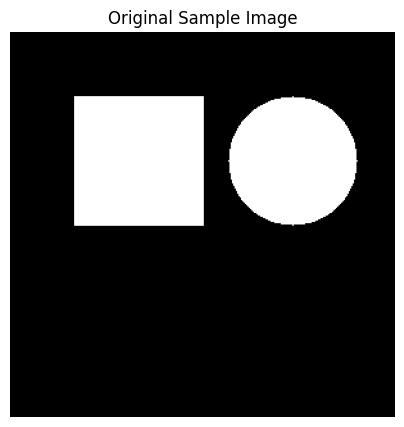

In [4]:

# Create a black image
img = np.zeros((300, 300, 3), dtype=np.uint8)

# Draw white shapes
cv2.rectangle(img, (50, 50), (150, 150), (255, 255, 255), -1)
cv2.circle(img, (220, 100), 50, (255, 255, 255), -1)

# Save the image
cv2.imwrite("sample_image.png", img)

# Display the image
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Sample Image")
plt.axis("off")
plt.show()


Image Shape: (300, 300, 3)
Image Data Type: uint8


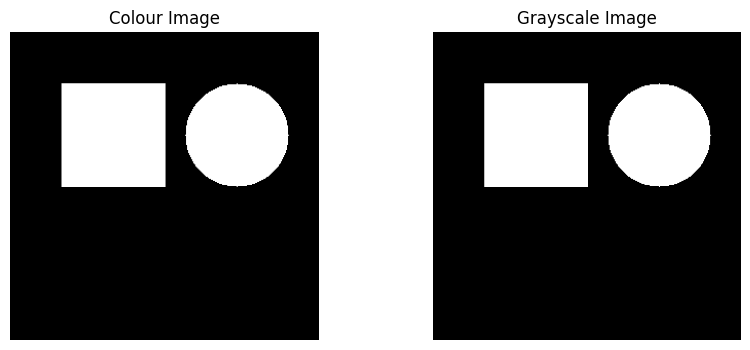

In [5]:

# Load colour image
color_img = cv2.imread("sample_image.png")

# Convert colour image into grayscale
gray_img = cv2.cvtColor(color_img, cv2.COLOR_BGR2GRAY)

# Display image information
print("Image Shape:", color_img.shape)
print("Image Data Type:", color_img.dtype)

# Display both images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB))
plt.title("Colour Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_img, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()


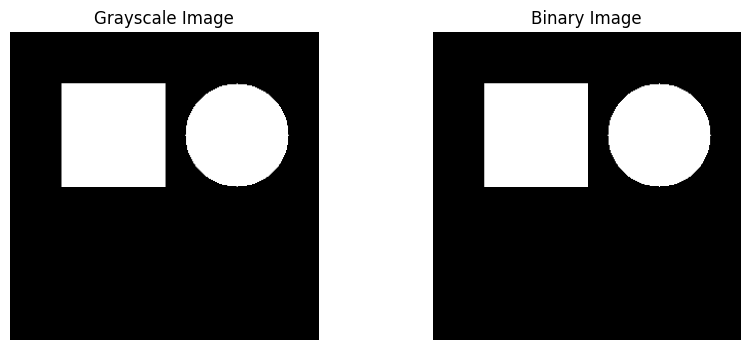

In [6]:

# Convert grayscale image into binary
_, binary_img = cv2.threshold(
    gray_img, 127, 255, cv2.THRESH_BINARY
)

# Display original and binary images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_img, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_img, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.show()


In [7]:

# Create a 5x5 kernel
kernel = np.ones((5, 5), np.uint8)

# Apply erosion
erosion = cv2.erode(binary_img, kernel, iterations=1)

# Apply dilation
dilation = cv2.dilate(binary_img, kernel, iterations=1)

# Apply opening
opening = cv2.morphologyEx(
    binary_img, cv2.MORPH_OPEN, kernel
)

# Apply closing
closing = cv2.morphologyEx(
    binary_img, cv2.MORPH_CLOSE, kernel
)

print("All four morphological operations completed!")


All four morphological operations completed!


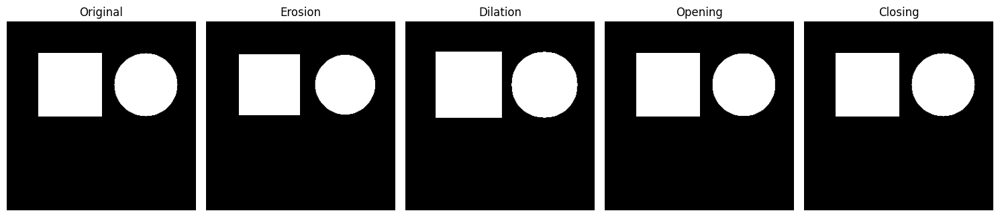

In [8]:

images = [
    binary_img,
    erosion,
    dilation,
    opening,
    closing
]

titles = [
    "Original",
    "Erosion",
    "Dilation",
    "Opening",
    "Closing"
]

plt.figure(figsize=(15, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


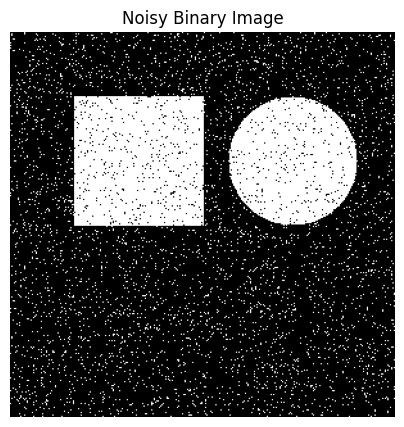

In [9]:

# Create a noisy binary image
noisy_img = binary_img.copy()

# Add random white and black noise
noise = np.random.randint(0, 100, noisy_img.shape)

noisy_img[noise < 5] = 255
noisy_img[noise > 95] = 0

plt.figure(figsize=(5, 5))
plt.imshow(noisy_img, cmap="gray")
plt.title("Noisy Binary Image")
plt.axis("off")
plt.show()


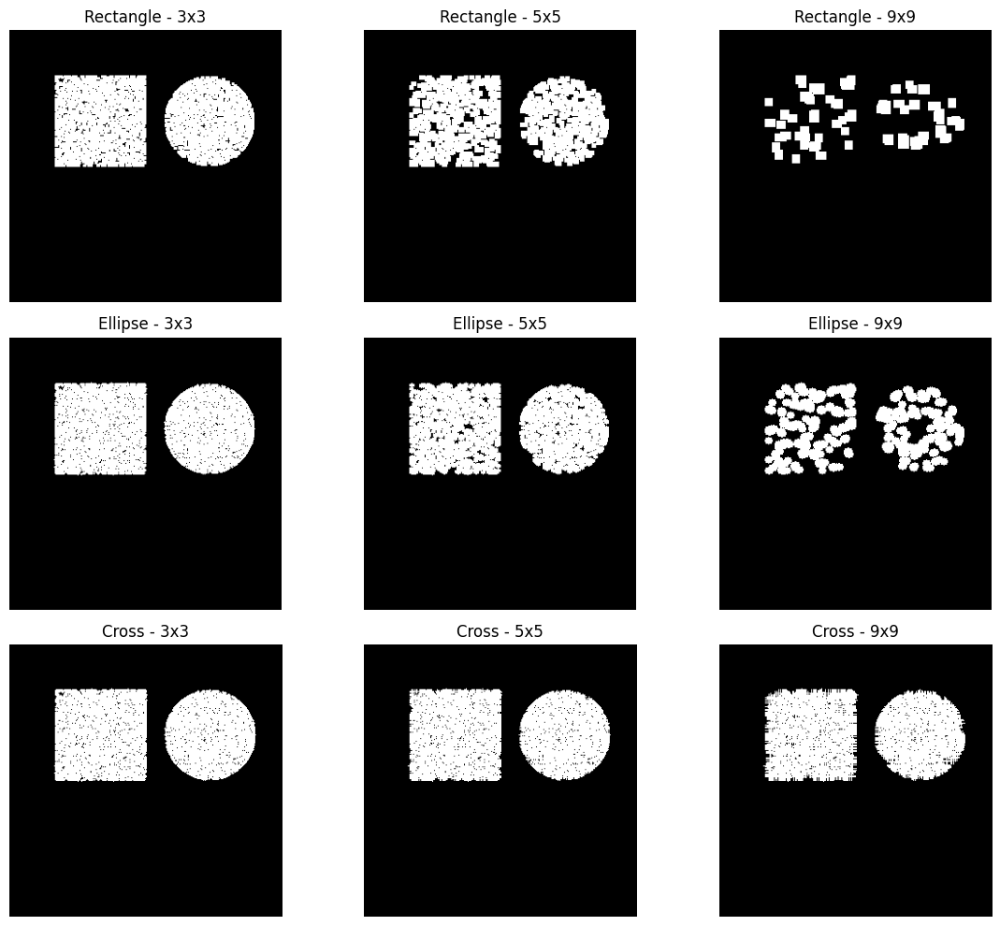

In [10]:

kernel_shapes = {
    "Rectangle": cv2.MORPH_RECT,
    "Ellipse": cv2.MORPH_ELLIPSE,
    "Cross": cv2.MORPH_CROSS
}

kernel_sizes = [3, 5, 9]

plt.figure(figsize=(12, 10))

plot_number = 1

for shape_name, shape_type in kernel_shapes.items():
    for size in kernel_sizes:

        kernel = cv2.getStructuringElement(
            shape_type, (size, size)
        )

        result = cv2.morphologyEx(
            noisy_img, cv2.MORPH_OPEN, kernel
        )

        plt.subplot(3, 3, plot_number)
        plt.imshow(result, cmap="gray")
        plt.title(f"{shape_name} - {size}x{size}")
        plt.axis("off")

        plot_number += 1

plt.tight_layout()
plt.show()


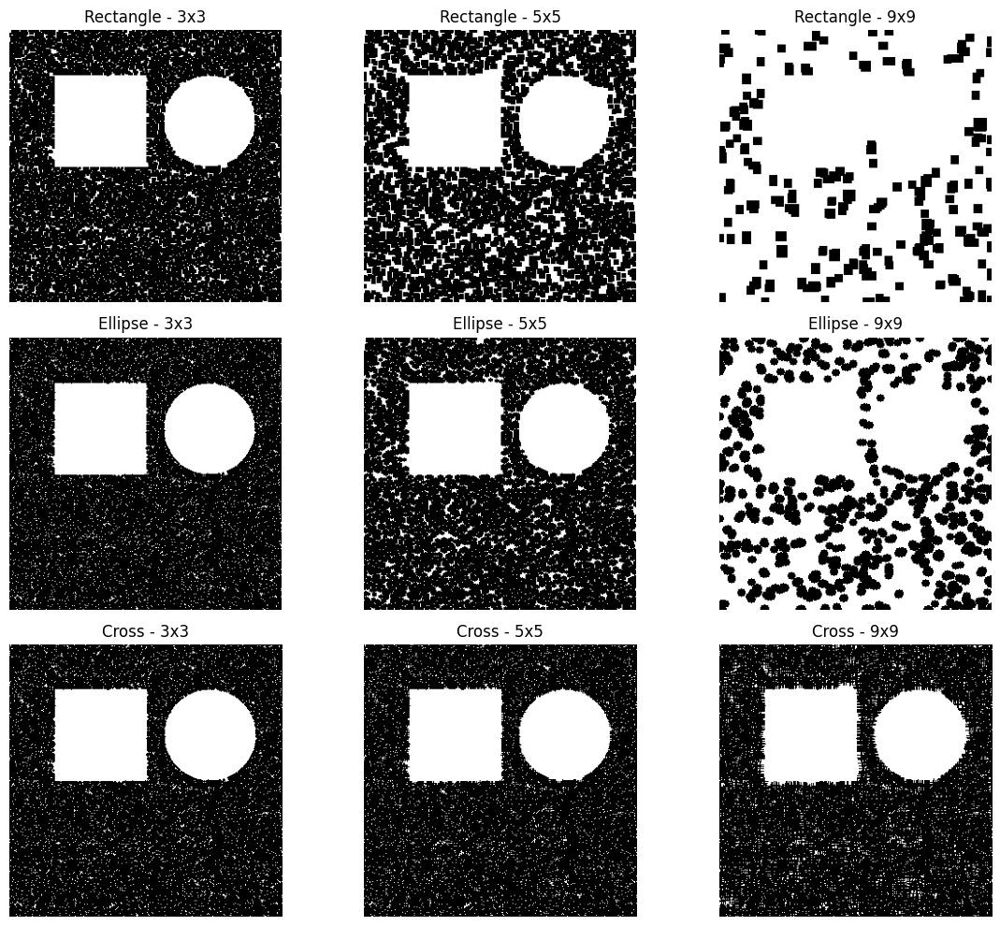

In [11]:

plt.figure(figsize=(12, 10))

plot_number = 1

for shape_name, shape_type in kernel_shapes.items():
    for size in kernel_sizes:

        kernel = cv2.getStructuringElement(
            shape_type, (size, size)
        )

        result = cv2.morphologyEx(
            noisy_img, cv2.MORPH_CLOSE, kernel
        )

        plt.subplot(3, 3, plot_number)
        plt.imshow(result, cmap="gray")
        plt.title(f"{shape_name} - {size}x{size}")
        plt.axis("off")

        plot_number += 1

plt.tight_layout()
plt.show()


## Working Principle of Morphological Operations

### 1. Erosion
Erosion is an image-processing operation that reduces the size of white regions in a binary image. It removes small white noise and makes objects thinner. It is useful for removing unwanted small particles from images.

### 2. Dilation
Dilation increases the size of white regions in an image. It makes objects thicker and helps fill small gaps. It is useful when objects have broken or disconnected boundaries.

### 3. Opening
Opening is performed by applying erosion followed by dilation. It removes small white noise while maintaining the overall shape of larger objects. It is useful for cleaning noisy images before object detection.

### 4. Closing
Closing is performed by applying dilation followed by erosion. It fills small black holes and gaps inside white objects. It is useful for improving incomplete object boundaries.

### Real-Life Applications

- Erosion: Removing small unwanted particles from medical images.
- Dilation: Connecting broken parts of characters in scanned documents.
- Opening: Removing small noise from surveillance camera images.
- Closing: Filling small gaps in detected objects.

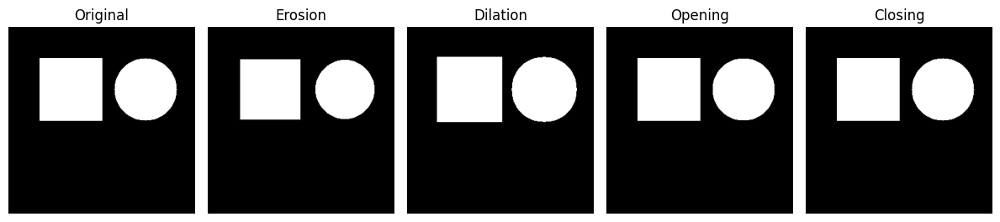

Morphology graph saved successfully!


In [12]:

import os

os.makedirs("plots", exist_ok=True)

plt.figure(figsize=(12, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.savefig("plots/morphology_grid.png")
plt.show()

print("Morphology graph saved successfully!")


In [13]:

from google.colab import files

files.download("plots/morphology_grid.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# TASK 2: BITWISE OPERATIONS AND IMAGE HISTOGRAMS

## Objective
To understand bitwise operations and analyse image intensity, brightness and contrast using OpenCV.

## Topics
1. Bitwise AND
2. Bitwise OR
3. Bitwise XOR
4. Bitwise NOT
5. Grayscale Histogram
6. Colour Histogram
7. Brightness and Contrast Adjustment


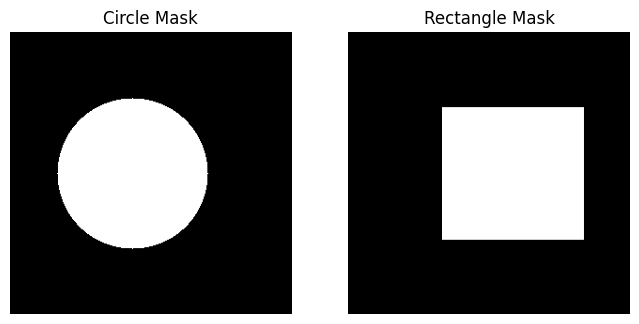

In [14]:

# Create a black canvas
mask1 = np.zeros((300, 300), dtype=np.uint8)
mask2 = np.zeros((300, 300), dtype=np.uint8)

# Draw a white circle
cv2.circle(mask1, (130, 150), 80, 255, -1)

# Draw a white rectangle
cv2.rectangle(mask2, (100, 80), (250, 220), 255, -1)

# Display both masks
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(mask1, cmap="gray")
plt.title("Circle Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask2, cmap="gray")
plt.title("Rectangle Mask")
plt.axis("off")

plt.show()


In [15]:

# Apply bitwise operations

bitwise_and = cv2.bitwise_and(mask1, mask2)
bitwise_or = cv2.bitwise_or(mask1, mask2)
bitwise_xor = cv2.bitwise_xor(mask1, mask2)
bitwise_not = cv2.bitwise_not(mask1)

print("All bitwise operations completed!")


All bitwise operations completed!


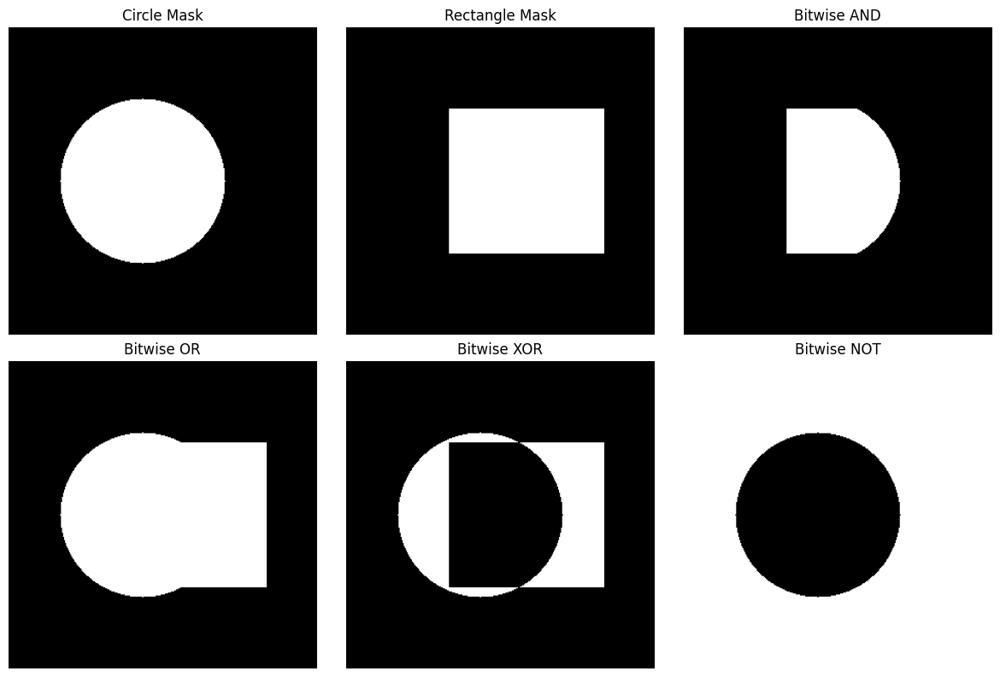

In [16]:

images = [
    mask1,
    mask2,
    bitwise_and,
    bitwise_or,
    bitwise_xor,
    bitwise_not
]

titles = [
    "Circle Mask",
    "Rectangle Mask",
    "Bitwise AND",
    "Bitwise OR",
    "Bitwise XOR",
    "Bitwise NOT"
]

plt.figure(figsize=(12, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [18]:

from google.colab import files

uploaded = files.upload()


Saving phooootooooo (1).jpg to phooootooooo (1).jpg


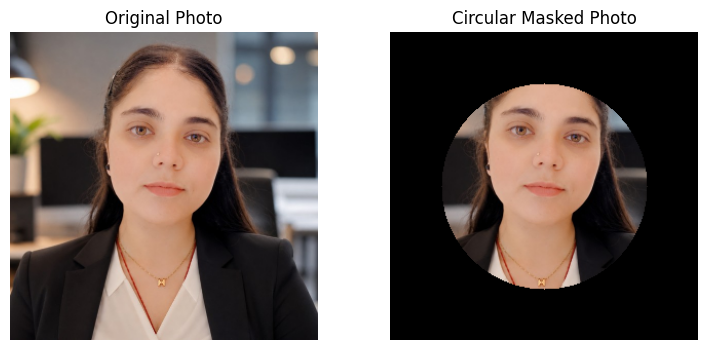

In [19]:

# Read uploaded image
image_path = next(iter(uploaded.keys()))
photo = cv2.imread(image_path)

# Resize image
photo = cv2.resize(photo, (300, 300))

# Create a circular mask
mask = np.zeros((300, 300), dtype=np.uint8)
cv2.circle(mask, (150, 150), 100, 255, -1)

# Extract circular region
masked_image = cv2.bitwise_and(
    photo, photo, mask=mask
)

# Display original and masked image
plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(photo, cv2.COLOR_BGR2RGB))
plt.title("Original Photo")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(masked_image, cv2.COLOR_BGR2RGB))
plt.title("Circular Masked Photo")
plt.axis("off")

plt.show()


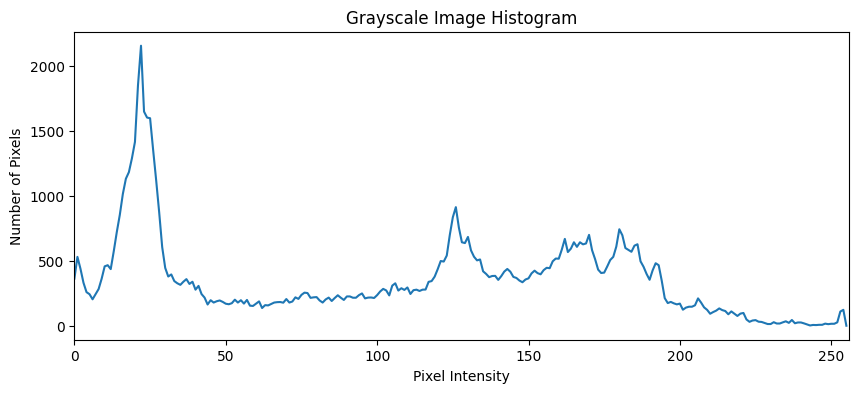

In [20]:

# Convert photo into grayscale
gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)

# Calculate histogram
hist = cv2.calcHist(
    [gray], [0], None, [256], [0, 256]
)

# Plot histogram
plt.figure(figsize=(10, 4))

plt.plot(hist)
plt.title("Grayscale Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.xlim([0, 256])

plt.show()


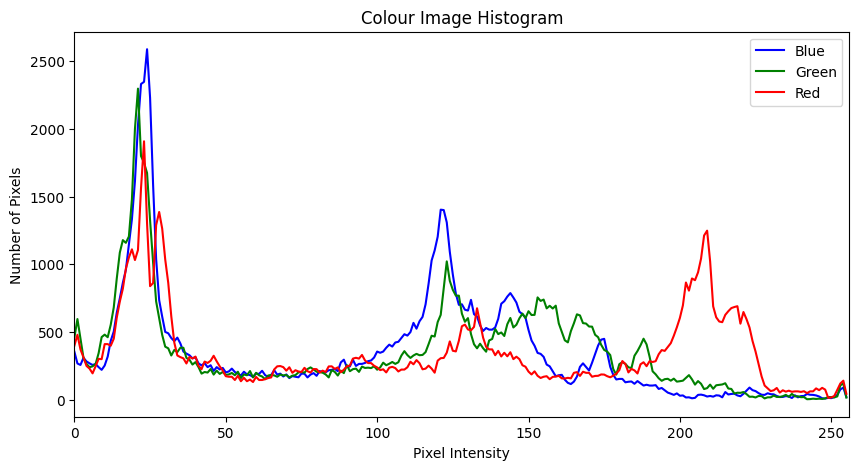

In [21]:

# Define channel colours and names
colors = ('b', 'g', 'r')
channel_names = ('Blue', 'Green', 'Red')

plt.figure(figsize=(10, 5))

# Calculate each channel histogram
for i, color in enumerate(colors):

    hist = cv2.calcHist(
        [photo], [i], None, [256], [0, 256]
    )

    plt.plot(hist, color=color, label=channel_names[i])

plt.title("Colour Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.legend()
plt.xlim([0, 256])

plt.show()


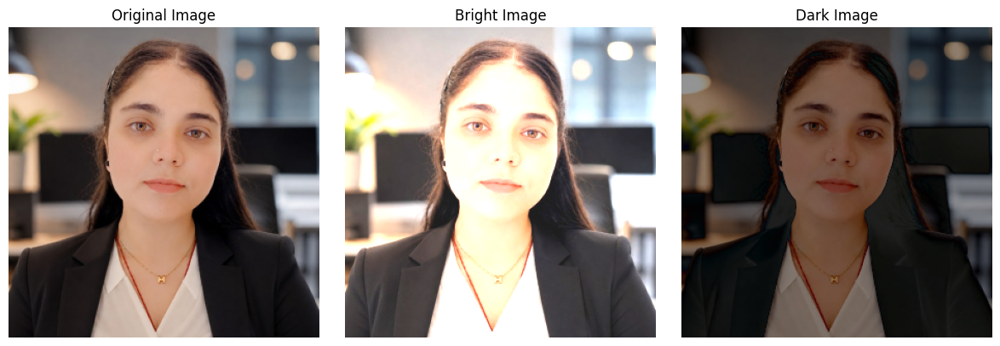

In [22]:

# Increase contrast and brightness
bright_img = cv2.convertScaleAbs(
    photo, alpha=1.5, beta=30
)

# Decrease contrast and brightness
dark_img = cv2.convertScaleAbs(
    photo, alpha=0.7, beta=-30
)

# Display all three images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(photo, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(bright_img, cv2.COLOR_BGR2RGB))
plt.title("Bright Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(dark_img, cv2.COLOR_BGR2RGB))
plt.title("Dark Image")
plt.axis("off")

plt.tight_layout()
plt.show()


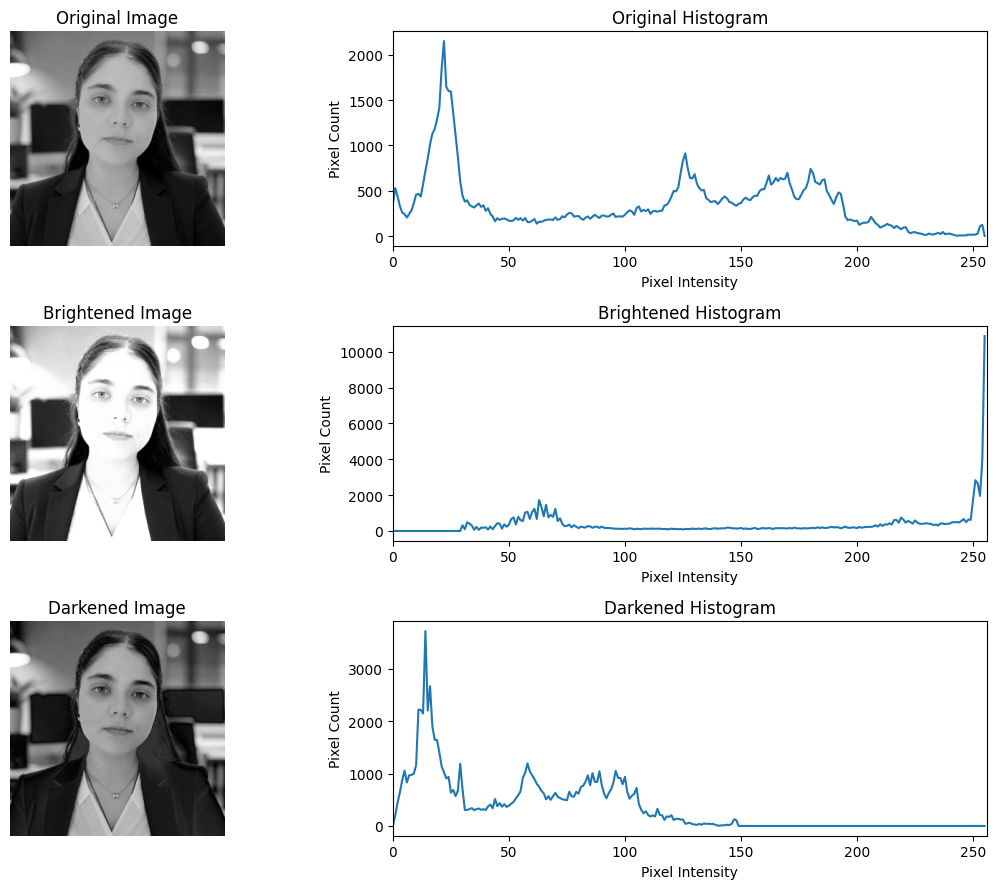

In [23]:

# Convert all images to grayscale
original_gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)
bright_gray = cv2.cvtColor(bright_img, cv2.COLOR_BGR2GRAY)
dark_gray = cv2.cvtColor(dark_img, cv2.COLOR_BGR2GRAY)

all_images = [
    original_gray,
    bright_gray,
    dark_gray
]

titles = [
    "Original",
    "Brightened",
    "Darkened"
]

plt.figure(figsize=(12, 9))

for i in range(3):

    plt.subplot(3, 2, 2*i + 1)
    plt.imshow(all_images[i], cmap="gray")
    plt.title(titles[i] + " Image")
    plt.axis("off")

    plt.subplot(3, 2, 2*i + 2)

    hist = cv2.calcHist(
        [all_images[i]], [0], None, [256], [0, 256]
    )

    plt.plot(hist)
    plt.title(titles[i] + " Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Pixel Count")
    plt.xlim([0, 256])

plt.tight_layout()
plt.show()


## Working Principle of Bitwise Operations and Image Histograms

### 1. Bitwise AND
Bitwise AND compares two images pixel by pixel. It displays white pixels only where both images have white pixels. It is useful for selecting specific regions of an image.

### 2. Bitwise OR
Bitwise OR combines white regions from both images. It is useful for combining image masks and creating overlays.

### 3. Bitwise XOR
Bitwise XOR displays pixels where the two images have different values. It is useful for identifying differences between two binary images.

### 4. Bitwise NOT
Bitwise NOT reverses the pixel values of an image. Black pixels become white, and white pixels become black.

### 5. Image Histogram
An image histogram represents the distribution of pixel intensity values. It helps analyse image brightness, contrast and exposure.

### 6. Brightness and Contrast
Brightness and contrast can be adjusted using the formula:

New Pixel = Alpha × Original Pixel + Beta

Alpha controls contrast, while Beta controls brightness.

A higher Alpha value generally increases contrast, while a lower value reduces contrast. A positive Beta value increases brightness, while a negative Beta value decreases brightness.

### Real-Life Applications

- Medical imaging: Selecting specific regions of an image.
- Digital photography: Adjusting brightness and contrast.
- Image editing: Combining multiple image regions.
- Computer vision: Analysing image quality before object detection.

In [25]:
import os

os.makedirs("plots", exist_ok=True)

# Save bitwise comparison
plt.figure(figsize=(12, 8))

# Redefine the titles and images locally to avoid conflict with overwritten variables
bitwise_images = [
    mask1,
    mask2,
    bitwise_and,
    bitwise_or,
    bitwise_xor,
    bitwise_not
]

bitwise_titles = [
    "Circle Mask",
    "Rectangle Mask",
    "Bitwise AND",
    "Bitwise OR",
    "Bitwise XOR",
    "Bitwise NOT"
]

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(bitwise_images[i], cmap="gray")
    plt.title(bitwise_titles[i])
    plt.axis("off")

plt.tight_layout()
plt.savefig("plots/bitwise_operations.png")
plt.close()

# Save histogram comparison
plt.figure(figsize=(10, 5))

plt.plot(cv2.calcHist([gray], [0], None, [256], [0, 256]))
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Pixel Count")

plt.savefig("plots/histogram_comparison.png")
plt.close()

print("Task 2 graphs saved successfully!")

Task 2 graphs saved successfully!


In [26]:

from google.colab import files

files.download("plots/bitwise_operations.png")
files.download("plots/histogram_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Task 3: Face Detection using YuNet

## Objective
The objective of this task is to detect human faces in images using the pretrained YuNet face detection model.

## Working
YuNet is a lightweight face detection model. It detects faces and provides:
- Face bounding boxes
- Five facial landmarks
- Confidence scores

In [27]:
!wget -O face_detection_yunet_2023mar.onnx https://huggingface.co/opencv/opencv_zoo/resolve/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx

--2026-11-01 15:26:08--  https://huggingface.co/opencv/opencv_zoo/resolve/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx
Resolving huggingface.co (huggingface.co)... 52.85.132.22, 52.85.132.6, 52.85.132.34, ...
Connecting to huggingface.co (huggingface.co)|52.85.132.22|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/6835c1a834109f3463ba2273/d3fbb6028fc86125755b70f69f428ebbf39fbb01cfa5df3e3dbe1563148ae349?user_id=public&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27face_detection_yunet_2023mar.onnx%3B+filename%3D%22face_detection_yunet_2023mar.onnx%22%3B&xip=7BwQibaVHKY&X-Xet-Cas-Uid=public&Expires=1793550368&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjgzNWMxYTgzNDEwOWYzNDYzYmEyMjczL2QzZmJiNjAyOGZjODYxMjU3NTViNzBmNjlmNDI4ZWJiZjM5ZmJiMDFjZmE1ZGYzZTNkYmUxNTYzMTQ4YWUzNDlcXD91c2VyX2lkPXB1YmxpYyZyZXNwb25zZS1jb250ZW50LWRpc3Bvc2l0aW9uPSo

In [28]:
from google.colab import files

uploaded_faces = files.upload()

Saving Image 1.jpg to Image 1.jpg


Number of faces detected: 9


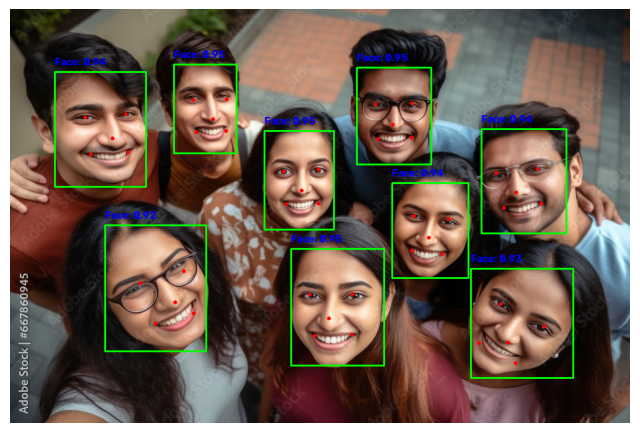

In [29]:
import cv2
import matplotlib.pyplot as plt
import os

model_path = "face_detection_yunet_2023mar.onnx"

os.makedirs("task3_results", exist_ok=True)

def detect_faces(image_path):

    image = cv2.imread(image_path)

    if image is None:
        print("Image could not be loaded:", image_path)
        return

    height, width = image.shape[:2]

    detector = cv2.FaceDetectorYN_create(
        model_path,
        "",
        (width, height),
        0.7,
        0.3,
        5000
    )

    _, faces = detector.detect(image)

    result = image.copy()

    if faces is not None:

        for face in faces:

            x, y, w, h = face[:4].astype(int)

            # Draw face bounding box
            cv2.rectangle(
                result,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            # Draw five facial landmarks
            landmarks = face[4:14].reshape(5, 2)

            for point in landmarks:
                px, py = point.astype(int)
                cv2.circle(result, (px, py), 3, (0, 0, 255), -1)

            confidence = face[-1]

            cv2.putText(
                result,
                f"Face: {confidence:.2f}",
                (x, max(y - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 0, 0),
                2
            )

        print("Number of faces detected:", len(faces))

    else:
        print("No face detected.")

    output_path = "task3_results/" + os.path.basename(image_path)

    cv2.imwrite(output_path, result)

    plt.figure(figsize=(8, 6))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()


for image_name in uploaded_faces.keys():
    detect_faces(image_name)

In [30]:
image_name = list(uploaded_faces.keys())[0]

test_image = cv2.imread(image_name)
height, width = test_image.shape[:2]

thresholds = [0.5, 0.7, 0.9]

for threshold in thresholds:

    detector = cv2.FaceDetectorYN_create(
        model_path,
        "",
        (width, height),
        threshold,
        0.3,
        5000
    )

    _, detected_faces = detector.detect(test_image)

    count = 0 if detected_faces is None else len(detected_faces)

    print("Threshold:", threshold)
    print("Faces detected:", count)
    print("-------------------")

Threshold: 0.5
Faces detected: 9
-------------------
Threshold: 0.7
Faces detected: 9
-------------------
Threshold: 0.9
Faces detected: 9
-------------------


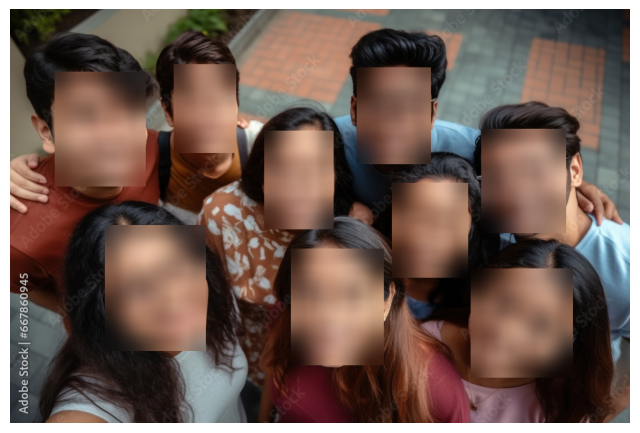

True

In [31]:
privacy_image = cv2.imread(image_name)

height, width = privacy_image.shape[:2]

detector = cv2.FaceDetectorYN_create(
    model_path,
    "",
    (width, height),
    0.7,
    0.3,
    5000
)

_, detected_faces = detector.detect(privacy_image)

if detected_faces is not None:

    for face in detected_faces:

        x, y, w, h = face[:4].astype(int)

        x1 = max(0, x)
        y1 = max(0, y)
        x2 = min(width, x + w)
        y2 = min(height, y + h)

        face_region = privacy_image[y1:y2, x1:x2]

        if face_region.size > 0:
            blurred = cv2.GaussianBlur(face_region, (51, 51), 30)
            privacy_image[y1:y2, x1:x2] = blurred

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(privacy_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

cv2.imwrite("task3_results/privacy_blurred.jpg", privacy_image)

## Conclusion

In this task, I implemented face detection using the pretrained YuNet model.
The model detected faces, generated bounding boxes, identified five facial
landmarks, and displayed confidence scores.

I also tested different confidence thresholds and applied Gaussian blur
to detected face regions to demonstrate privacy protection.

## Applications
1. Face detection systems
2. Attendance monitoring
3. Video surveillance
4. Face privacy protection
5. Human-computer interaction

In [32]:
from google.colab import files

uploaded_video = files.upload()

video_path = next(iter(uploaded_video.keys()))

print("Uploaded video:", video_path)

Saving video.mp4 to video.mp4
Uploaded video: video.mp4


In [33]:
import cv2
import time
import os

video = cv2.VideoCapture(video_path)

if not video.isOpened():
    print("Error: Video could not be opened.")

else:
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

    fps_input = video.get(cv2.CAP_PROP_FPS)

    os.makedirs("task3_results", exist_ok=True)

    output_path = "task3_results/yunet_face_video.mp4"

    writer = cv2.VideoWriter(
        output_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps_input if fps_input > 0 else 25,
        (width, height)
    )

    detector = cv2.FaceDetectorYN_create(
        model_path,
        "",
        (width, height),
        0.7,
        0.3,
        5000
    )

    frame_count = 0
    start_time = time.time()

    while True:

        success, frame = video.read()

        if not success:
            break

        detector.setInputSize((width, height))

        _, faces = detector.detect(frame)

        if faces is not None:

            for face in faces:

                x, y, w, h = face[:4].astype(int)

                cv2.rectangle(
                    frame,
                    (x, y),
                    (x + w, y + h),
                    (0, 255, 0),
                    2
                )

                for point in face[4:14].reshape(5, 2):
                    px, py = point.astype(int)
                    cv2.circle(frame, (px, py), 3, (0, 0, 255), -1)

                confidence = face[-1]

                cv2.putText(
                    frame,
                    f"Face: {confidence:.2f}",
                    (x, max(y - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (255, 0, 0),
                    2
                )

        writer.write(frame)
        frame_count += 1

    end_time = time.time()

    total_time = end_time - start_time
    average_fps = frame_count / total_time if total_time > 0 else 0

    video.release()
    writer.release()

    print("Total frames processed:", frame_count)
    print("Processing time:", round(total_time, 2), "seconds")
    print("Average FPS:", round(average_fps, 2))
    print("Output saved:", output_path)

Total frames processed: 431
Processing time: 26.34 seconds
Average FPS: 16.36
Output saved: task3_results/yunet_face_video.mp4


In [34]:
from IPython.display import Video, display

display(Video(
    "task3_results/yunet_face_video.mp4",
    embed=True
))

## Real-Time Face Detection – Conclusion

In this experiment, I applied the YuNet face detection model to a video.
The model processed the video frame by frame and detected visible faces
using bounding boxes and facial landmarks.

I also calculated the average FPS to understand the processing speed
of the face detection system.

FPS (Frames Per Second) represents the number of video frames processed
in one second. Higher FPS indicates faster processing.

# Task 4: Object Detection using YOLOv8

## Objective
The objective of this task is to detect and identify multiple objects
in images and videos using the pretrained YOLOv8 deep learning model.

## Expected Output
- Object bounding boxes
- Object class labels
- Confidence scores
- Video object detection
- Object detection performance analysis

In [35]:
from ultralytics import YOLO

# Load pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")
print("Number of classes:", len(model.names))

YOLOv8 model loaded successfully!
Number of classes: 80


In [36]:
from google.colab import files

uploaded_objects = files.upload()

image_paths = list(uploaded_objects.keys())

print("Uploaded images:", image_paths)

Saving SWARNA PATHAK RESUME.pdf to SWARNA PATHAK RESUME.pdf
Uploaded images: ['SWARNA PATHAK RESUME.pdf']


In [38]:
import cv2
import matplotlib.pyplot as plt
import os

os.makedirs("task4_results", exist_ok=True)

image_results = []

# Define supported image extensions
supported_extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff")

for image_path in image_paths:
    # Skip non-image files such as PDFs
    ext = os.path.splitext(image_path)[1].lower()
    if not ext.endswith(supported_extensions):
        print(f"Skipping unsupported file: {image_path}. Please upload an image file (JPG, PNG, etc.) instead.")
        continue

    results = model(image_path, conf=0.25)

    image_results.extend(results)

    # Draw boxes, labels and confidence scores
    output_image = results[0].plot()

    # Convert BGR to RGB
    output_image = cv2.cvtColor(
        output_image,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(10, 7))
    plt.imshow(output_image)
    plt.title("YOLOv8 Object Detection")
    plt.axis("off")
    plt.show()

    # Save result
    cv2.imwrite(
        "task4_results/" + os.path.basename(image_path),
        results[0].plot()
    )

Skipping unsupported file: SWARNA PATHAK RESUME.pdf. Please upload an image file (JPG, PNG, etc.) instead.


In [40]:
# Use a valid image file instead of the PDF
test_image = "Image 1.jpg"

confidence_values = [0.25, 0.50, 0.75]

for conf_value in confidence_values:

    results = model(
        test_image,
        conf=conf_value,
        verbose=False
    )

    detected_count = len(results[0].boxes)

    print("Confidence:", conf_value)
    print("Objects detected:", detected_count)
    print("-------------------------")

Confidence: 0.25
Objects detected: 11
-------------------------
Confidence: 0.5
Objects detected: 8
-------------------------
Confidence: 0.75
Objects detected: 5
-------------------------


In [41]:
iou_values = [0.30, 0.50, 0.70]

for iou_value in iou_values:

    results = model(
        test_image,
        conf=0.25,
        iou=iou_value,
        verbose=False
    )

    print("IoU threshold:", iou_value)
    print("Objects detected:", len(results[0].boxes))
    print("-------------------------")

IoU threshold: 0.3
Objects detected: 7
-------------------------
IoU threshold: 0.5
Objects detected: 9
-------------------------
IoU threshold: 0.7
Objects detected: 11
-------------------------


In [42]:
from collections import Counter

class_counts = Counter()

for result in image_results:

    for class_id in result.boxes.cls.tolist():

        class_name = model.names[int(class_id)]

        class_counts[class_name] += 1

print("Object Detection Summary:")

for name, count in class_counts.items():
    print(name, ":", count)

Object Detection Summary:


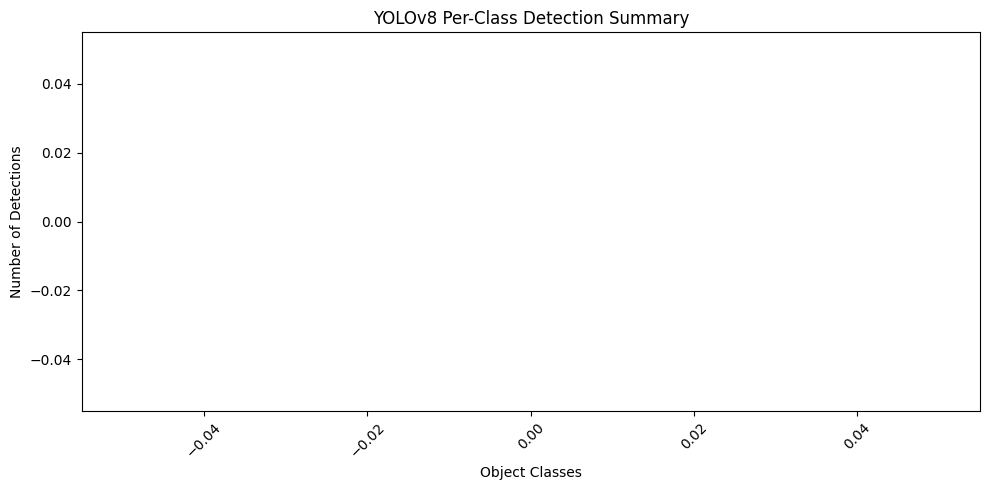

In [43]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("YOLOv8 Per-Class Detection Summary")
plt.xlabel("Object Classes")
plt.ylabel("Number of Detections")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("task4_results/yolo_class_summary.png")
plt.show()

In [44]:
print("Uploaded images:", image_paths)
print("Number of results:", len(image_results))

for result in image_results:
    print("Detections:", len(result.boxes))

Uploaded images: ['SWARNA PATHAK RESUME.pdf']
Number of results: 0


In [46]:
from collections import Counter
import matplotlib.pyplot as plt
import os

class_counts = Counter()
supported_extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff")

# Filter out any non-image files from image_paths
valid_image_paths = [
    path for path in image_paths
    if os.path.splitext(path)[1].lower() in supported_extensions
]

# If no valid images are in image_paths, fall back to our uploaded "Image 1.jpg"
if not valid_image_paths and os.path.exists("Image 1.jpg"):
    valid_image_paths = ["Image 1.jpg"]

for image_path in valid_image_paths:
    results = model.predict(
        source=image_path,
        conf=0.15,
        verbose=False
    )

    for result in results:
        for class_id in result.boxes.cls.tolist():
            class_name = model.names[int(class_id)]
            class_counts[class_name] += 1

print("Detected object classes:", class_counts)

Detected object classes: Counter({'person': 11})


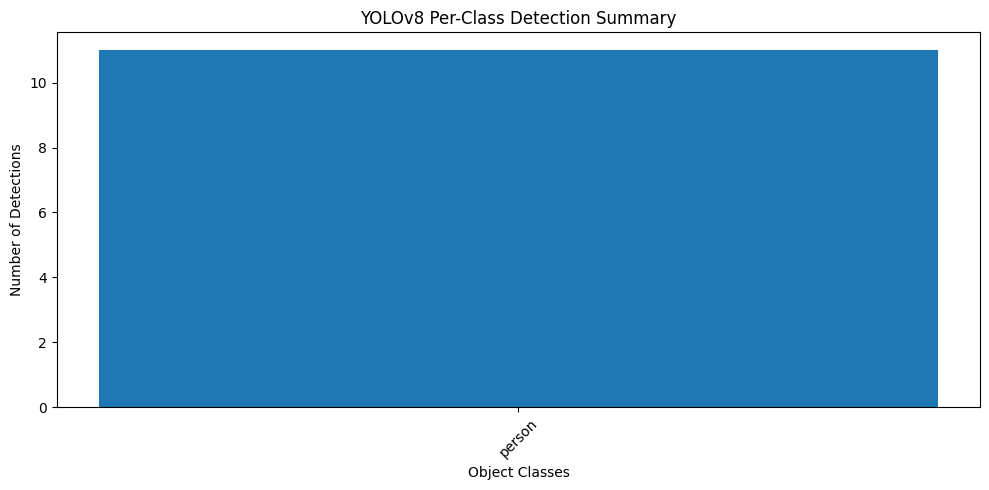

In [47]:
if len(class_counts) > 0:

    plt.figure(figsize=(10, 5))

    plt.bar(
        class_counts.keys(),
        class_counts.values()
    )

    plt.title("YOLOv8 Per-Class Detection Summary")
    plt.xlabel("Object Classes")
    plt.ylabel("Number of Detections")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.savefig("task4_results/yolo_class_summary.png")
    plt.show()

else:
    print("No objects detected. Please upload clear images and try again.")

## How YOLO Works

YOLO is a single-stage object detection algorithm.

It processes an image in one forward pass and predicts:
1. Bounding box coordinates
2. Object class probabilities
3. Confidence scores

Non-Maximum Suppression (NMS) removes duplicate overlapping
bounding boxes and keeps the most suitable detections.

## Advantages
- Fast object detection
- Detects multiple objects in one image
- Supports many object categories
- Suitable for real-time applications

## Limitations
- Small objects can be difficult to detect.
- Occlusion may affect detection accuracy.
- Detection performance depends on image quality.
- The Nano model may be less accurate than larger models.

## Conclusion

In this task, I used the pretrained YOLOv8 Nano model
to detect multiple objects in images.

I displayed bounding boxes, object labels and confidence
scores. I also experimented with confidence and IoU
thresholds and created a per-class detection chart.

YOLOv8 is useful for applications such as smart surveillance,
traffic monitoring, retail analytics and autonomous systems.

In [48]:
uploaded_video = files.upload()

yolo_video_path = next(iter(uploaded_video.keys()))

Saving video.mp4 to video (1).mp4


In [49]:
import time

start_time = time.time()

video_results = model.predict(
    source=yolo_video_path,
    conf=0.25,
    iou=0.7,
    save=True,
    project="task4_results",
    name="yolo_video",
    exist_ok=True,
    verbose=False
)

end_time = time.time()

frame_count = len(video_results)

processing_time = end_time - start_time

average_fps = (
    frame_count / processing_time
    if processing_time > 0 else 0
)

print("Frames processed:", frame_count)
print("Processing time:", round(processing_time, 2), "seconds")
print("Average processing FPS:", round(average_fps, 2))

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /content/runs/detect/task4_results/yolo_video
Frames processed: 431
Processing time: 42.56 seconds
Average processing FPS: 10.13


In [50]:
from IPython.display import Video, display
import os

processed_video = os.path.join(
    "task4_results",
    "yolo_video",
    os.path.basename(yolo_video_path)
)

display(Video(processed_video, embed=True))

# Task 5: Integrated Pipeline & Final Comparison

## Objective
The objective of this task is to combine classical image processing,
YuNet face detection and YOLOv8 object detection into one integrated
computer vision pipeline.

## Expected Output
- Face detection with green bounding boxes.
- Object detection with red bounding boxes.
- Combined annotated video.
- FPS comparison of YuNet, YOLO and the combined pipeline.
- Final comparison table.

In [51]:
print("Video path:", video_path)
print("YOLO model:", model)
print("YuNet model:", model_path)

Video path: video.mp4
YOLO model: YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=

In [52]:
from google.colab import files

uploaded_video = files.upload()
video_path = next(iter(uploaded_video.keys()))

Saving video.mp4 to video (2).mp4


In [53]:
import cv2
import os
import time
import numpy as np
import matplotlib.pyplot as plt

video = cv2.VideoCapture(video_path)

frames = []

while len(frames) < 100:

    success, frame = video.read()

    if not success:
        break

    frames.append(frame)

video.release()

print("Total frames collected:", len(frames))

Total frames collected: 100


In [54]:
def run_yunet(frame):

    height, width = frame.shape[:2]

    detector = cv2.FaceDetectorYN_create(
        model_path,
        "",
        (width, height),
        0.7,
        0.3,
        5000
    )

    _, faces = detector.detect(frame)

    return faces

In [55]:
def run_yolo(frame):

    results = model.predict(
        source=frame,
        conf=0.25,
        verbose=False
    )

    return results[0]

In [56]:
def integrated_pipeline(frame):

    output = frame.copy()

    # YuNet face detection
    faces = run_yunet(frame)

    if faces is not None:

        for face in faces:

            x, y, w, h = face[:4].astype(int)

            cv2.rectangle(
                output,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            cv2.putText(
                output,
                f"Face {face[-1]:.2f}",
                (x, max(y - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )

    # YOLO object detection
    yolo_result = run_yolo(frame)

    for box in yolo_result.boxes:

        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)

        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        class_name = model.names[class_id]

        cv2.rectangle(
            output,
            (x1, y1),
            (x2, y2),
            (0, 0, 255),
            2
        )

        cv2.putText(
            output,
            f"{class_name} {confidence:.2f}",
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 0, 255),
            2
        )

    return output

In [57]:
output_folder = "task5_results"

os.makedirs(output_folder, exist_ok=True)

height, width = frames[0].shape[:2]

output_path = output_folder + "/integrated_pipeline.mp4"

video_writer = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    25,
    (width, height)
)

for frame in frames:

    combined_frame = integrated_pipeline(frame)

    video_writer.write(combined_frame)

video_writer.release()

print("Integrated video saved successfully!")

Integrated video saved successfully!


In [58]:
from IPython.display import Video, display

display(Video(output_path, embed=True))

In [59]:
def calculate_fps(detection_function, frames):

    start_time = time.time()

    for frame in frames:
        detection_function(frame)

    end_time = time.time()

    total_time = end_time - start_time

    fps = len(frames) / total_time if total_time > 0 else 0

    return fps


# YuNet FPS
face_fps = calculate_fps(run_yunet, frames)

# YOLO FPS
yolo_fps = calculate_fps(run_yolo, frames)

# Combined pipeline FPS
combined_fps = calculate_fps(integrated_pipeline, frames)


print("YuNet FPS:", round(face_fps, 2))
print("YOLO FPS:", round(yolo_fps, 2))
print("Combined FPS:", round(combined_fps, 2))

YuNet FPS: 11.59
YOLO FPS: 11.88
Combined FPS: 6.13


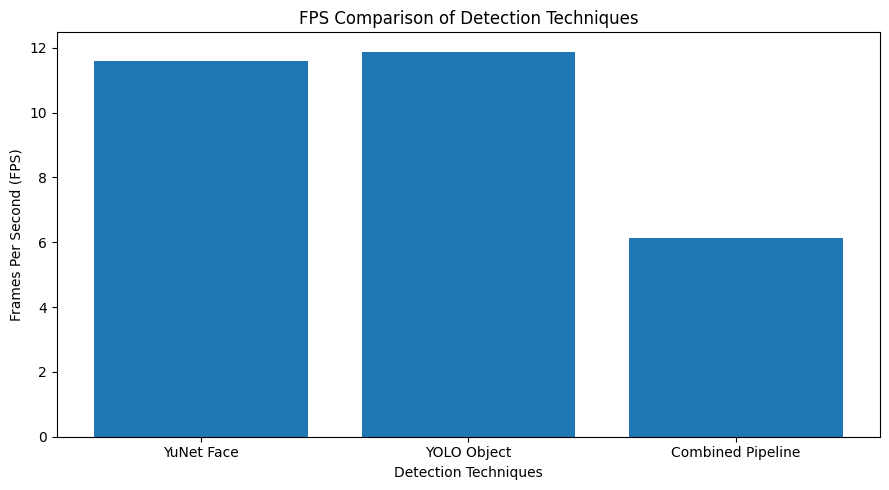

In [60]:
fps_names = ["YuNet Face", "YOLO Object", "Combined Pipeline"]

fps_values = [face_fps, yolo_fps, combined_fps]

plt.figure(figsize=(9, 5))

plt.bar(fps_names, fps_values)

plt.title("FPS Comparison of Detection Techniques")
plt.xlabel("Detection Techniques")
plt.ylabel("Frames Per Second (FPS)")

plt.tight_layout()

plt.savefig("task5_results/fps_comparison.png")

plt.show()

In [61]:
import pandas as pd

comparison_data = {
    "Technique": [
        "Morphological Operations",
        "Bitwise Operations & Histograms",
        "YuNet Face Detection",
        "YOLOv8 Object Detection"
    ],

    "Type": [
        "Classical",
        "Classical",
        "Deep Learning",
        "Deep Learning"
    ],

    "What It Detects": [
        "Image noise and shape changes",
        "Pixel regions and intensity distribution",
        "Human faces",
        "80 COCO object categories"
    ],

    "Lighting Robustness": [
        "Depends on threshold and image quality",
        "Depends on pixel intensity",
        "Affected by poor lighting",
        "Affected by poor lighting"
    ],

    "Approx. FPS": [
        "Not measured",
        "Not measured",
        round(face_fps, 2),
        round(yolo_fps, 2)
    ],

    "Best Use Case": [
        "Image preprocessing",
        "Image masking and analysis",
        "Face detection",
        "General object detection"
    ]
}

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df)

comparison_df.to_csv(
    "task5_results/final_comparison.csv",
    index=False
)

,Technique,Type,What It Detects,Lighting Robustness,Approx. FPS,Best Use Case
0,Morphological Operations,Classical,Image noise and shape changes,Depends on threshold and image quality,Not measured,Image preprocessing
1,Bitwise Operations & Histograms,Classical,Pixel regions and intensity distribution,Depends on pixel intensity,Not measured,Image masking and analysis
2,YuNet Face Detection,Deep Learning,Human faces,Affected by poor lighting,11.59,Face detection
3,YOLOv8 Object Detection,Deep Learning,80 COCO object categories,Affected by poor lighting,11.88,General object detection


# Final Project Conclusion

In this project, I explored different computer vision techniques,
starting from classical image processing and moving towards
deep-learning-based detection.

I implemented morphological operations, bitwise operations,
image histograms, YuNet face detection and YOLOv8 object detection.

Finally, I combined YuNet and YOLOv8 into an integrated pipeline
to detect human faces and everyday objects in video frames.

I also measured the FPS of individual detection methods and
the combined pipeline to understand their processing performance.

## Final Reflection

Classical image processing techniques are useful because they
are simple and computationally efficient. YuNet is suitable
for face detection, while YOLOv8 can identify multiple object
categories.

Combining these techniques creates a useful computer vision
system for applications such as smart surveillance, traffic
monitoring and retail analytics.

For low-power edge devices, lightweight models such as YOLOv8n
are useful. For cloud-based applications, larger models can be
considered when higher detection accuracy is required.